# Event rate oscillogram with adjustable reconstruction smearing

This notebook is derived from `evt_rate_calc.ipynb`. It reuses that notebook's
flux, cross-section, angular-resolution and oscillation-probability setup
(Sections 1-4), then reimplements the **Event rate oscillogram** section with
an adjustable Gaussian smearing model for reconstruction:

- **Reconstructed energy**: Gaussian with a *non-zero* bias (mean != E_true)
  and an adjustable resolution (standard deviation).
- **Reconstructed zenith angle (cos theta)**: Gaussian with *zero* bias and an
  adjustable resolution, defaulting to the measured angular resolution used
  in `evt_rate_calc.ipynb` (`angular_resolution.txt`).

## 1. Atmospheric neutrino flux

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interp
from scipy.interpolate import RegularGridInterpolator

with open('hms-nu-20-01-000.d') as f:
    with open('hms-nu-20-01-n3650.d') as l:
        lines_min = (line for line in f if 'average' not in line and 'Enu' not in line)
        lines_max = (line for line in l if 'average' not in line and 'Enu' not in line)
        all_flux_data_min = np.loadtxt(lines_min)
        all_flux_data_max = np.loadtxt(lines_max)  

        flux_data_numu = (all_flux_data_min[:, [0, 1]] + all_flux_data_max[:, [0, 1]]) / 2
        numu_uncertainty = np.abs(all_flux_data_min[:, [0, 1]] - all_flux_data_max[:, [0, 1]]) / 2

        flux_data_numubar = (all_flux_data_min[:, [0, 2]] + all_flux_data_max[:, [0, 2]]) / 2
        numubar_uncertainty = np.abs(all_flux_data_min[:, [0, 2]] - all_flux_data_max[:, [0, 2]]) / 2

        flux_data_nue = (all_flux_data_min[:, [0, 3]] + all_flux_data_max[:, [0, 3]]) / 2
        nue_uncertainty = np.abs(all_flux_data_min[:, [0, 3]] - all_flux_data_max[:, [0, 3]]) / 2

        flux_data_nuebar = (all_flux_data_min[:, [0, 4]] + all_flux_data_max[:, [0, 4]]) / 2
        nuebar_uncertainty = np.abs(all_flux_data_min[:, [0, 4]] - all_flux_data_max[:, [0, 4]]) / 2

In [48]:
n_energy = 101
energies = all_flux_data_min[:n_energy, 0]
num_cos = len(all_flux_data_min) // n_energy
cos_bins_centers = np.linspace(-0.95, 0.95, num_cos)


def make_interpolator(data):
    """Create a 2D flux interpolator from [energy, value] blocks."""
    values = data[:, 1].reshape(num_cos, n_energy)
    return RegularGridInterpolator(
        (cos_bins_centers, energies),
        values,
        method="linear",
        bounds_error=False,
        fill_value=0,
    )


flux_data = {
    "numu": flux_data_numu,
    "numubar": flux_data_numubar,
    "nue": flux_data_nue,
    "nuebar": flux_data_nuebar,
}

uncertainty_data = {
    "numu": numu_uncertainty,
    "numubar": numubar_uncertainty,
    "nue": nue_uncertainty,
    "nuebar": nuebar_uncertainty,
}

flux_interpolators = {
    flavor: make_interpolator(data)
    for flavor, data in flux_data.items()
}

uncertainty_interpolators = {
    flavor: make_interpolator(data)
    for flavor, data in uncertainty_data.items()
}


def get_flux(cos_theta, energy, flavor="numu", uncertainty=False):
    """Return interpolated flux or its uncertainty for a flavor."""
    interpolators = uncertainty_interpolators if uncertainty else flux_interpolators
    points = np.column_stack([np.atleast_1d(cos_theta), np.atleast_1d(energy)])
    return interpolators[flavor](points)

## 2. Xsec from GENIE

In [49]:
import uproot

energy_bins = np.linspace(0.5, 8.0, 62)
energy_bins_centers = (energy_bins[:-1] + energy_bins[1:]) / 2
energy_bins_edges = energy_bins
# Load the ROOT cross-section graphs.
file = uproot.open("/Users/taozhou/Downloads/genie_xsec/v3_06_00/NULL/AR2320i00000-k250-e1000/data/xsec_graphs.root")
graph_names = {
    "numu": "nu_mu_Ar40",
    "numubar": "nu_mu_bar_Ar40",
    "nue": "nu_e_Ar40",
    "nuebar": "nu_e_bar_Ar40",
}

xsec_interpolators = {}
xsecs = {}
for flavor, graph_name in graph_names.items():
    graph = file[graph_name]["tot_cc;1"]
    x_values = np.asarray(graph.member("fX"))
    y_values = np.asarray(graph.member("fY"))
    xsec_interpolators[flavor] = interp.interp1d(
        x_values,
        y_values,
        bounds_error=False,
        fill_value=0,
    )
    xsecs[flavor] = xsec_interpolators[flavor](energy_bins_centers)

# Preserve the original numu variables used by downstream cells.
inter_xy = xsec_interpolators["numu"]
xsec = xsecs["numu"]
xsec_numu = xsecs["numu"]
xsec_numubar = xsecs["numubar"]
xsec_nue = xsecs["nue"]
xsec_nuebar = xsecs["nuebar"]

# Convert cross section from 10^-38 cm^2 to m^2 and scale by argon count.
conv = 1e-38 * 1e-4
noar = 20 * 1e3 * 1e6 * 6.022e23 / 39.948
scaled_xsecs = {flavor: conv * noar * values for flavor, values in xsecs.items()}
scaled_xsec = scaled_xsecs["numu"]

## 3. Angular resolution

In [50]:
x_ang, y_ang = np.loadtxt("angular_resolution.txt", delimiter=",", skiprows=1, unpack=True)
inter_xy_ang = interp.interp1d(
    x_ang,
    y_ang,
    kind="linear",
    bounds_error=False,
    # Data only covers up to x_ang[-1] = 8.9116 GeV. Above that, hold the
    # angular resolution at its last measured value instead of dropping to
    # 0 (which would make sigma=0 and break the cos-theta smearing for any
    # E_grid point above ~8.9 GeV).
    fill_value=(y_ang[0], y_ang[-1]),
)
angular_res = inter_xy_ang(energy_bins_centers)

## 4. Oscillation probability

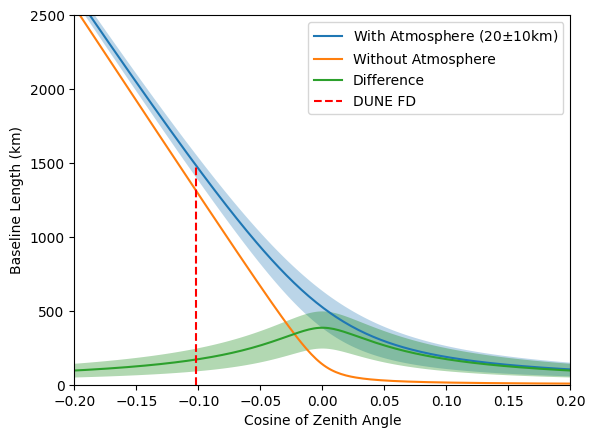

In [51]:
from numpy import deg2rad


r = 6371 # earth radius in km
d = 20 # average altitude of neutrino production in the atmosphere in km https://arxiv.org/abs/1502.03916
s = 1.5 # depth of DUNE FD in km

def zenith_to_baseline(x, d=20):
    """
    Convert zenith angle (cosine) to baseline length in km.
    """
    sqrt = np.sqrt(4*x**2*(s-r)**2-4*(s**2-2*r*s-d**2-2*r*d))
    L = 1/2 * (-2*x*(r-s) + sqrt)
    return L

def approx(x):
    """
    without atmosphere thickness and depth of DUNE FD
    """
    if x > 0:
        L = 0
    else:
        L = -2*r*x
    return L

zenith_table  = np.linspace(-1, 1, 1000)
plt.plot(zenith_table, zenith_to_baseline(zenith_table), label="With Atmosphere (20$\pm$10km)")
plt.fill_between(zenith_table, zenith_to_baseline(zenith_table, d=10), zenith_to_baseline(zenith_table, d=30), alpha=0.3)
plt.plot(zenith_table, zenith_to_baseline(zenith_table, d=0), label="Without Atmosphere")
plt.plot(zenith_table, zenith_to_baseline(zenith_table)-zenith_to_baseline(zenith_table, d=0), label="Difference")
plt.fill_between(zenith_table, zenith_to_baseline(zenith_table, d=10)-zenith_to_baseline(zenith_table, d=0), zenith_to_baseline(zenith_table, d=30)-zenith_to_baseline(zenith_table, d=0), alpha=0.3, color = 'green', edgecolor=None)
plt.vlines(np.cos(deg2rad(95.85)),0,zenith_to_baseline(np.cos(deg2rad(95.85))),linestyle='--', color='r', label="DUNE FD")
plt.xlabel("Cosine of Zenith Angle")
plt.ylabel("Baseline Length (km)")
plt.ylim(0, 2500)
plt.xlim(-0.2, 0.2)
plt.legend()
plt.show()

In [52]:
from oscillation_tools import (km, prob_full, calc_bin_centers, prob_2f, OscillationParameters, MeV, ThreeFlavorOscillation)
osc_model_vac = ThreeFlavorOscillation(rho=0, channel="mu_mu")
osc_model = ThreeFlavorOscillation(channel="mu_mu")
osc_model_ant = ThreeFlavorOscillation(channel="mu_mu", antineutrino=True)

## 5. Event rate oscillogram: reconstruction smearing model

### Adjustable reconstruction parameters

**Energy** — reconstructed energy is drawn from a Gaussian with a non-zero
bias and an adjustable resolution:

$$E_{reco} \sim \mathcal{N}\big((1+b_E)\,E_{true},\ \sigma_E = r_E\,E_{true}\big)$$

*Educated guess for the defaults:* LArTPC calorimetric reconstruction of
neutrino CC interactions in the atmospheric-neutrino energy range
(0.5-10 GeV) tends to **underestimate** the true neutrino energy, because
some final-state energy is not captured (sub-Cherenkov/sub-threshold
protons and neutrons, escaping neutrons, nuclear binding energy). We take
`E_BIAS_FRAC = -0.05` (5% underestimation) and `E_RES_FRAC = 0.15`
(15% fractional resolution, a representative single-number stand-in for
DUNE's CDR/TDR-level performance across a mix of quasi-elastic-like and
more inelastic topologies in this energy range). Both are adjustable below.

**Zenith angle** — reconstructed $\cos\theta$ is drawn from a Gaussian with
*zero* bias and an adjustable resolution:

$$\cos\theta_{reco} \sim \mathcal{N}\big(\cos\theta_{true},\ \sigma_{\cos\theta}\big)$$

where $\sigma_{\cos\theta} = \sin\theta_{true}\cdot(\texttt{ANGULAR\_RES\_SCALE}\times\theta_{res}(E_{true}))$
and $\theta_{res}(E)$ is the measured angular resolution curve from
Section 3 (`angular_resolution.txt`), i.e. the same quantity
`evt_rate_calc.ipynb` already uses for its angular-resolution systematic.
`ANGULAR_RES_SCALE = 1.0` reproduces that default resolution exactly;
set it to e.g. 0.8 / 1.2 to study +-20% variations.

In [57]:
# ------------------------------------------------------------------
# Reconstruction-smearing parameters (adjustable)
# ------------------------------------------------------------------
E_BIAS_FRAC = -0.05    # mean(E_reco)  = (1 + E_BIAS_FRAC) * E_true
E_RES_FRAC  = 0.15     # sigma(E_reco) = E_RES_FRAC * E_true

COS_BIAS          = 0.0   # mean(cos_reco) = cos_true + COS_BIAS (kept at 0)
ANGULAR_RES_SCALE = 0.01   # sigma(cos_reco) uses ANGULAR_RES_SCALE * measured angular resolution

time_factor = 3 * 365.25 * 24 * 3600  # 3 years in seconds

In [58]:
cos_grid = np.linspace(-0.95, 0.95, 100)   # x axis (true cos theta)
E_grid   = np.linspace(0.5, 10, 100)       # y axis (true energy, GeV)
energy_bin_width = E_grid[1] - E_grid[0]
d_cos            = cos_grid[1] - cos_grid[0]

xsec_grid        = conv * noar * inter_xy(E_grid)
angular_res_grid = inter_xy_ang(E_grid) * ANGULAR_RES_SCALE  # degrees, scaled

Prob   = np.zeros((len(E_grid), len(cos_grid)))
R      = np.zeros((len(E_grid), len(cos_grid)))
R_stat = np.zeros_like(R)
R_syst = np.zeros_like(R)
R_tot  = np.zeros_like(R)

for i, E in enumerate(E_grid):
    for j, cos in enumerate(cos_grid):
        flux  = get_flux(cos, E)[0]
        dflux = get_flux(cos, E, uncertainty=True)[0]
        L     = zenith_to_baseline(cos)
        P     = osc_model(L_km=L, E_GeV=E)

        cell = flux * P * xsec_grid[i] * 2*np.pi * time_factor * energy_bin_width * d_cos
        R[i, j] = cell
        Prob[i, j] = P
        # Poisson
        R_stat[i, j] = np.sqrt(max(cell, 0))

        # Flux systematic
        s_flux = (dflux / flux) * cell if flux > 0 else 0

        # Angular resolution systematic (truth-level, same convention as
        # evt_rate_calc.ipynb; ANGULAR_RES_SCALE already folded into
        # angular_res_grid above).
        delta     = 1e-5
        dL_dcos   = (zenith_to_baseline(cos + delta) - zenith_to_baseline(cos - delta)) / (2 * delta)
        sin_theta = np.sqrt(1 - cos**2)
        dL        = abs(dL_dcos) * sin_theta * np.radians(angular_res_grid[i])

        cell_u = flux * osc_model(L_km=L + dL, E_GeV=E) * xsec_grid[i] * 2*np.pi * time_factor * energy_bin_width * d_cos
        cell_l = flux * osc_model(L_km=L - dL, E_GeV=E) * xsec_grid[i] * 2*np.pi * time_factor * energy_bin_width * d_cos
        s_ang  = 0.5 * abs(cell_u - cell_l)

        R_syst[i, j] = np.hypot(s_flux, s_ang)
        R_tot[i, j]  = np.hypot(R_stat[i, j], R_syst[i, j])

In [59]:
# ------------------------------------------------------------------
# Reconstructed (smeared) event rate.
#
# The detector response is modeled as two independent Gaussian
# migrations applied to the truth-level rate R(E_true, cos_true):
#
#   1. cos(theta) migration: bias = COS_BIAS (= 0), sigma = the local
#      angular resolution converted from angle to cos(theta) via
#      sin(theta_true) -- the same convention used for the R_syst
#      angular term above.
#   2. Energy migration: bias = E_BIAS_FRAC * E_true, sigma =
#      E_RES_FRAC * E_true.
#
# Each kernel is truncated to (and renormalized within) the finite
# E_grid / cos_grid window, i.e. we assume no events migrate outside
# the analysis range. Because the two migrations act along orthogonal
# axes, applying them as two sequential matrix multiplications is
# equivalent to a single joint 2D convolution (order does not matter).
# ------------------------------------------------------------------

# Step 1: cos(theta) migration (per true-energy row)
sin_theta_local = np.sqrt(1 - cos_grid**2)
R_cos_smeared = np.zeros_like(R)
for i, E in enumerate(E_grid):
    ang_res_rad = np.radians(angular_res_grid[i])
    sigma_cos   = np.maximum(sin_theta_local * ang_res_rad, 1e-3 * abs(d_cos))

    # weights[j, k] = N(cos_grid[k]; mean=cos_grid[j]+COS_BIAS, sigma=sigma_cos[j]), row-normalized
    diff    = (cos_grid[None, :] - COS_BIAS) - cos_grid[:, None]
    weights = np.exp(-0.5 * (diff / sigma_cos[:, None]) ** 2)
    weights /= weights.sum(axis=1, keepdims=True)

    R_cos_smeared[i, :] = weights @ R[i, :]

# Step 2: energy migration (shared across all cos columns)
mu_E    = (1 + E_BIAS_FRAC) * E_grid
sigma_E = np.maximum(E_RES_FRAC * E_grid, 1e-3 * energy_bin_width)

# weights_E[i_true, i_reco] = N(E_grid[i_reco]; mean=mu_E[i_true], sigma=sigma_E[i_true]), row-normalized
diff_E    = E_grid[None, :] - mu_E[:, None]
weights_E = np.exp(-0.5 * (diff_E / sigma_E[:, None]) ** 2)
weights_E /= weights_E.sum(axis=1, keepdims=True)

R_smeared = weights_E.T @ R_cos_smeared   # [E_reco, cos_reco]
R_smeared = np.clip(R_smeared, 0, None)

print(f"Total truth-level events:   {R.sum():.1f}")
print(f"Total reconstructed events: {R_smeared.sum():.1f}  (edge migration outside the grid is not conserved)")

Total truth-level events:   2657.4
Total reconstructed events: 2657.4  (edge migration outside the grid is not conserved)


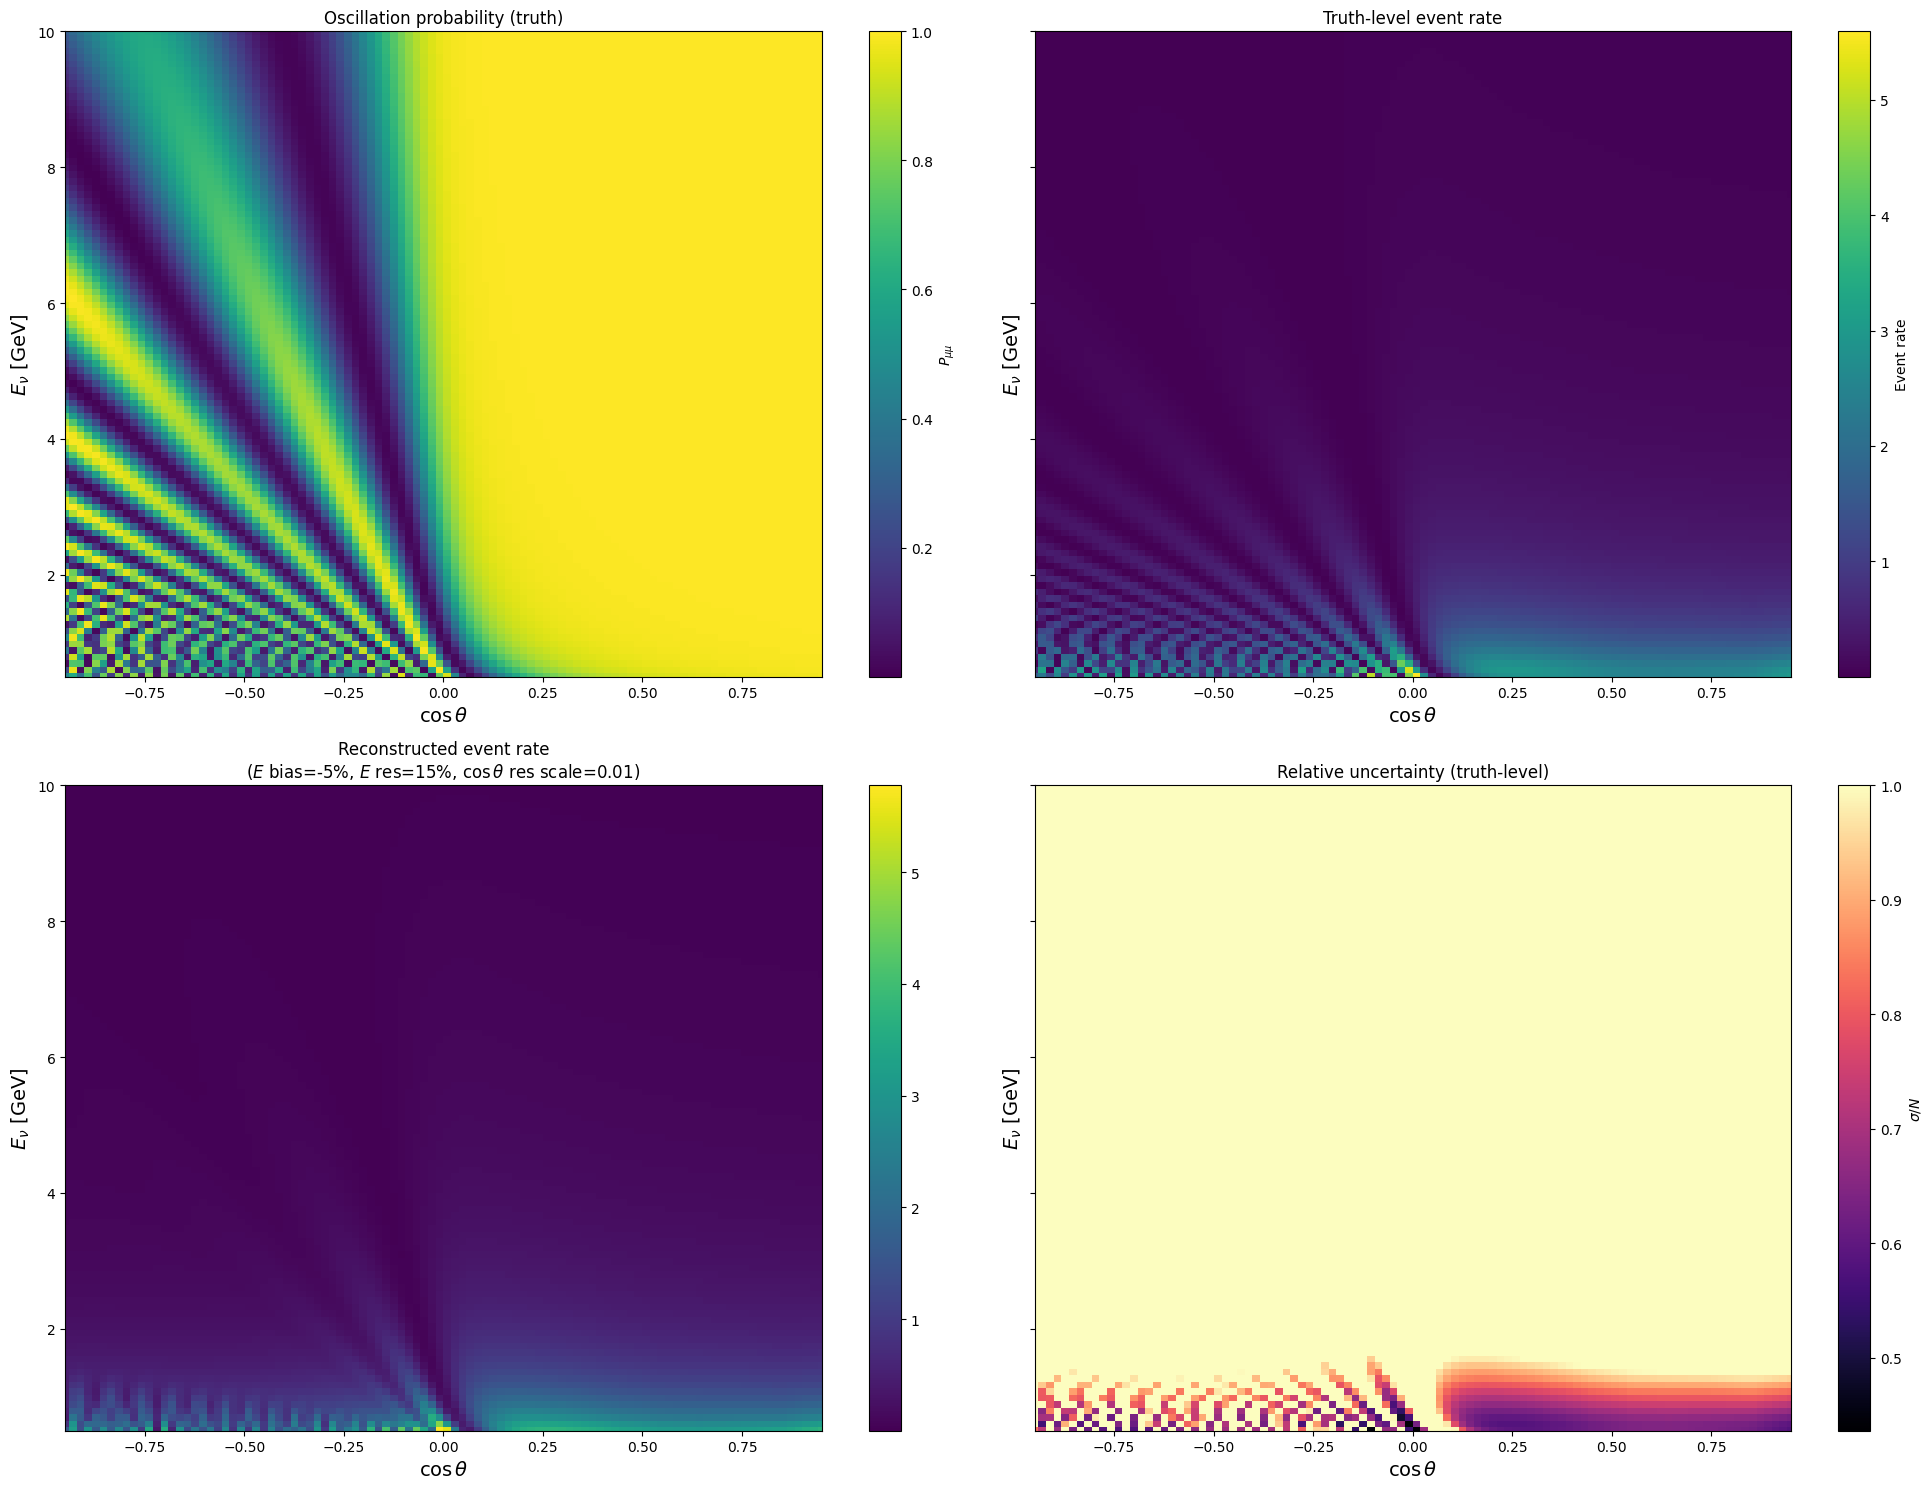

In [61]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(2, 2, figsize=(20, 15), sharey=True)

# Panel 1: oscillogram (truth)
pc2 = axes[0,0].pcolormesh(cos_grid, E_grid, Prob, shading='auto',
                          cmap='viridis', vmax=1.0)
fig.colorbar(pc2, ax=axes[0,0], label=r'$P_{\mu\mu}$')
axes[0,0].set_title('Oscillation probability (truth)')

# Panel 2: truth-level event rate
pc0 = axes[0,1].pcolormesh(cos_grid, E_grid, R, shading='auto', cmap='viridis')
fig.colorbar(pc0, ax=axes[0,1], label='Event rate')
axes[0,1].set_title('Truth-level event rate')

# Panel 3: reconstructed (energy + angle smeared) event rate
R_smeared_positive = R_smeared[R_smeared > 0]
vmin = R_smeared_positive.min() if R_smeared_positive.size else 1e-12
vmax = max(float(R_smeared.max()), vmin * 10.0)
R_smeared_plot = np.ma.masked_where(R_smeared <= 0, R_smeared)
pc3 = axes[1,0].pcolormesh(
    cos_grid,
    E_grid,
    R_smeared_plot,
    #norm=LogNorm(vmin=vmin, vmax=vmax),
    shading='auto',
    cmap='viridis',
)
fig.colorbar(pc3, ax=axes[1,0])
axes[1,0].set_title(
    'Reconstructed event rate\n'
    rf'($E$ bias={E_BIAS_FRAC:+.0%}, $E$ res={E_RES_FRAC:.0%}, '
    rf'$\cos\theta$ res scale={ANGULAR_RES_SCALE:.2f})'
)

# Panel 4: relative total uncertainty (truth-level)
rel_unc = np.divide(R_tot, R, out=np.zeros_like(R), where=R>0)
pc1 = axes[1,1].pcolormesh(cos_grid, E_grid, rel_unc, shading='auto',
                          cmap='magma', vmax=1.0)
fig.colorbar(pc1, ax=axes[1,1], label=r'$\sigma / N$')
axes[1,1].set_title('Relative uncertainty (truth-level)')

for ax in axes.flat:
    ax.set_xlabel(r'$\cos\theta$', fontsize=14)
    ax.set_ylabel(r'$E_\nu$ [GeV]', fontsize=14)
    ax.set_xlim(-0.95, 0.95)
    ax.set_ylim(0.5, 10)
plt.tight_layout()
plt.savefig('event_rate_oscillogram_reco_smeared.pdf', dpi=300)
plt.show()